# Numerical example: Change-point estimation under extended negative dependence

We compare five estimators of a single change in mean. We measure how accurately they locate the change and how often each scan detects it after separate null calibration.

We observe $Y_{n,i}=\Delta_n I(i\le k_{0,n})+X_i$, where $k_{0,n}=\lfloor0.4n\rfloor$. Candidate splits belong to $K_n=\{k:0.1n\le k\le0.9n\}$. We use $p=3/2$, $r=1$, $\ell(n)=\log(\mathrm e+n)$, and $a_n=(n\ell(n))^{1/p}/n$. The three signal settings are $\Delta_n=0$, $\Delta_n=a_n\ell(n)$, and $\Delta_n=2a_n$.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata


P = 1.5
DEPENDENCE_LEVELS = (0.0, 0.5, 0.9)
EPSILON = 0.10
TEST_LEVEL = 0.05
LOCAL_SIGNAL = 2.0
SAMPLE_SIZES = tuple(2**power for power in range(8, 17))
REPETITIONS = 2_000
CALIBRATION_REPETITIONS = 1_000
BATCH_SIZE = 32
SEED = 20261117
CALIBRATION_SEED = 20261118
METHODS = ("gap", "quadratic", "cusum", "weighted_quadratic", "wilcoxon")
METHOD_NAMES = {
    "gap": "Mean gap",
    "quadratic": "Quadratic",
    "cusum": "CUSUM",
    "weighted_quadratic": "Weighted quadratic",
    "wilcoxon": "Wilcoxon",
}
SIGNALS = ("log", "local")

## Noise model

We generate a radius $R$ with

$$P(R>x)=\frac{1}{(1+x)^p[1+\log(1+x)]^2},\qquad x\ge0.$$

Let $s$ be its median and $\xi$ an independent uniform sign. The variable $Z=\xi R/s$ has zero mean, finite $p$th absolute moment, and infinite $(p+\delta)$th absolute moment for every $\delta>0$. To sample $R$, draw $t$ from an exponential distribution of mean one, solve $pv+2\log(1+v)=t$, and use $R=\exp(v)-1$.

In each independent pair, draw $Z_j,W_j$ independently with the law of $Z$, and set $X_{2j-1}=Z_j$. With probability $\rho$ take $X_{2j}=-Z_j$, and otherwise take $X_{2j}=W_j$. For $u=F_Z(x)$ and $v=F_Z(y)$, the joint lower-orthant probability is $(1-\rho)uv+\rho(u+v-1)_+\le uv$. The upper-orthant inequality follows by taking complements, and independence across pairs gives extended negative dependence with constant one. We use $\rho=0,0.5,0.9$, including independence at $\rho=0$.

In [2]:
def radius_from_exponential(e):
    e = np.asarray(e, dtype=float)
    v = e / (P + 2.0)
    for _ in range(12):
        residual = P * v + 2.0 * np.log1p(v) - e
        derivative = P + 2.0 / (1.0 + v)
        v = v - residual / derivative
    return np.expm1(v)


MEDIAN_RADIUS = float(radius_from_exponential(np.log(2.0)))


def draw_marginal(rng, shape):
    radius = radius_from_exponential(rng.exponential(size=shape))
    signs = rng.choice(np.array([-1.0, 1.0]), size=shape)
    return signs * radius / MEDIAN_RADIUS


def draw_components(rng, repetitions, n):
    shape = (repetitions, (n + 1) // 2)
    return draw_marginal(rng, shape), draw_marginal(rng, shape), rng.random(shape)


def pair_noise(components, n, rho):
    z, w, uniforms = components
    x = np.empty((z.shape[0], 2 * z.shape[1]))
    x[:, 0::2] = z
    x[:, 1::2] = np.where(uniforms < rho, -z, w)
    return x[:, :n]

## Candidate scores

Write $A_{n,k}=\bar Y_{1:k}-\bar Y_{k+1:n}$ and $\omega_{n,k}=k(n-k)/n$. The sample variances of the two blocks are $s_L^2$ and $s_R^2$. Put

$$D_{n,k}=A_{n,k}^2-\frac{s_L^2}{k}-\frac{s_R^2}{n-k}.$$

Let $R_{n,i}$ denote the pooled rank of $Y_{n,i}$, with midranks for ties. All five estimators select the smallest maximizer of their score over the same $K_n$.

| Method | Score |
|---|---|
| Mean gap | $A_{n,k}^2$ |
| Quadratic | $D_{n,k}$ |
| CUSUM | $\omega_{n,k} A_{n,k}^2$ |
| Weighted quadratic | $\omega_{n,k} D_{n,k}$ |
| Wilcoxon | $$\left[\sum_{i=1}^k(R_{n,i}-(n+1)/2)\right]^2/\omega_{n,k}$$ |

The implementation computes $D_{n,k}$ using cumulative product sums of distinct observations in each block. The two weighted scores share the same split weight.

In [3]:
def split_scores(y):
    n = y.shape[1]
    # Products of block lengths can exceed the 32-bit integer range.
    k = np.arange((n + 9) // 10, (9 * n) // 10 + 1, dtype=np.int64)
    right_size = n - k
    weight = k * right_size / n

    prefix_sum = np.cumsum(y, axis=1)
    suffix_sum = np.cumsum(y[:, ::-1], axis=1)
    prefix_product_sum = np.cumsum(prefix_sum[:, :-1] * y[:, 1:], axis=1)
    suffix_product_sum = np.cumsum(suffix_sum[:, :-1] * y[:, -2::-1], axis=1)
    left = 2 * prefix_product_sum[:, k - 2] / (k * (k - 1))
    right = 2 * suffix_product_sum[:, right_size - 2] / (right_size * (right_size - 1))
    left_mean = prefix_sum[:, k - 1] / k
    right_mean = suffix_sum[:, right_size - 1] / right_size
    quadratic = left + right - 2 * left_mean * right_mean
    gap = (left_mean - right_mean) ** 2

    ranks = rankdata(y, axis=1, method="average")
    centered_rank_sum = np.cumsum(ranks, axis=1)[:, k - 1] - k * (n + 1) / 2
    wilcoxon = centered_rank_sum**2 / weight
    return k, (gap, quadratic, weight * gap, weight * quadratic, wilcoxon)

## Monte Carlo design

We use $n=2^8,\ldots,2^{16}$ and 2,000 evaluation replications. All methods use the same data. We use nested samples across $n$ and common draws across dependence levels and signal settings.

For localization, we report the mean absolute fraction error $\mathbb E|\widehat k_n-k_{0,n}|/n$ and the mean excess $\mathbb E[(L_n-0.1)_+]$, where $L_n=(|\Delta_n|/a_n)|\widehat k_n-k_{0,n}|/n$. For the quadratic estimator, this is the first excess moment from the change-point theorem. Under the null, we also report two quantiles of $a_n^{-2}\max_{k\in K_n}|D_{n,k}|$.

For detection, each method uses the maximum of its score over $K_n$. At every $n$ and $\rho$, we calibrate each scan using the 951st order statistic of 1,000 independently generated null scan maxima. The scan rejects when it strictly exceeds this critical value. The evaluation replications provide separate estimates of false alarms and power at the nominal 5% level. The critical values are specific to the simulated null model.

In [4]:
def collect_scores(repetitions, seed, dependence_levels, signals):
    rng = np.random.Generator(np.random.PCG64(seed))
    shape = (len(dependence_levels), len(SAMPLE_SIZES), repetitions, len(METHODS))
    null_maxima = np.empty(shape)
    null_scan = np.empty(shape[:-1])
    alternative_maxima = {signal: np.empty(shape) for signal in signals}
    location_errors = {signal: np.empty(shape) for signal in signals}
    for start in range(0, repetitions, BATCH_SIZE):
        stop = min(start + BATCH_SIZE, repetitions)
        components = draw_components(rng, stop - start, SAMPLE_SIZES[-1])
        for row, rho in enumerate(dependence_levels):
            noise = pair_noise(components, SAMPLE_SIZES[-1], rho)
            for column, n in enumerate(SAMPLE_SIZES):
                ell_n = np.log(np.e + n)
                a_n = (n * ell_n) ** (1 / P) / n
                k0 = 2 * n // 5
                x = noise[:, :n]
                _, scores = split_scores(x)
                target = (row, column, slice(start, stop))
                null_maxima[target] = np.column_stack([score.max(axis=1) for score in scores])
                null_scan[target] = np.abs(scores[1]).max(axis=1) / a_n**2
                ratios = {"log": ell_n, "local": LOCAL_SIGNAL}
                for signal in signals:
                    y = x.copy()
                    y[:, :k0] += ratios[signal] * a_n
                    k, scores = split_scores(y)
                    alternative_maxima[signal][target] = np.column_stack(
                        [score.max(axis=1) for score in scores]
                    )
                    estimates = np.column_stack([k[np.argmax(score, axis=1)] for score in scores])
                    location_errors[signal][target] = np.abs(estimates - k0) / n
    return null_maxima, null_scan, alternative_maxima, location_errors


def monte_carlo_se(values):
    return values.std(axis=0, ddof=1) / np.sqrt(len(values))


def simulate(dependence_levels=DEPENDENCE_LEVELS):
    calibration, _, _, _ = collect_scores(CALIBRATION_REPETITIONS, CALIBRATION_SEED,
                                          dependence_levels, ())
    # The (m+1) rank adjustment calibrates a strict upper-tail rule.
    index = min(int(np.ceil((CALIBRATION_REPETITIONS + 1) * (1 - TEST_LEVEL))),
                CALIBRATION_REPETITIONS) - 1
    critical_values = np.partition(calibration, index, axis=2)[:, :, index, :]
    null_maxima, null_scan, alternative_maxima, location_errors = collect_scores(
        REPETITIONS, SEED, dependence_levels, SIGNALS
    )
    localization = []
    detection = []
    scan = []
    for row, rho in enumerate(dependence_levels):
        for column, n in enumerate(SAMPLE_SIZES):
            ell_n = np.log(np.e + n)
            a_n = (n * ell_n) ** (1 / P) / n
            ratios = {"log": ell_n, "local": LOCAL_SIGNAL}
            critical = critical_values[row, column]
            false_alarms = null_maxima[row, column] > critical
            positive = {name: alternative_maxima[name][row, column] > critical for name in SIGNALS}
            for j, method in enumerate(METHODS):
                detection.append({
                    "rho": rho, "n": n, "method": method,
                    "critical_value": critical[j],
                    "false_alarm_rate": false_alarms[:, j].mean(),
                    "se_false_alarm": monte_carlo_se(false_alarms[:, j]),
                    "power_log": positive["log"][:, j].mean(),
                    "se_power_log": monte_carlo_se(positive["log"][:, j]),
                    "power_local": positive["local"][:, j].mean(),
                    "se_power_local": monte_carlo_se(positive["local"][:, j]),
                })
            for signal in SIGNALS:
                errors = location_errors[signal][row, column]
                excesses = np.maximum(ratios[signal] * errors - EPSILON, 0)
                differences = excesses - excesses[:, METHODS.index("cusum"), None]
                for j, method in enumerate(METHODS):
                    localization.append({
                        "rho": rho, "n": n, "signal": signal, "method": method,
                        "signal_ratio": ratios[signal], "weight": ell_n / n,
                        "mean_fraction_error": errors[:, j].mean(),
                        "se_fraction_error": monte_carlo_se(errors[:, j]),
                        "mean_excess": excesses[:, j].mean(),
                        "se_excess": monte_carlo_se(excesses[:, j]),
                        "weighted_mean_excess": (ell_n / n) * excesses[:, j].mean(),
                        "excess_minus_cusum": differences[:, j].mean(),
                        "paired_se_minus_cusum": monte_carlo_se(differences[:, j]),
                    })
            median, percentile_90 = np.quantile(null_scan[row, column], [0.5, 0.9])
            scan.append({
                "rho": rho, "n": n, "scan_median": median, "scan_q90": percentile_90,
                "false_alarm_at_a2": (null_maxima[row, column, :, 1] > a_n**2).mean(),
                "miss_log_at_a2": (alternative_maxima["log"][row, column, :, 1] <= a_n**2).mean(),
                "miss_local_at_a2": (alternative_maxima["local"][row, column, :, 1] <= a_n**2).mean(),
            })
    return {
        "localization_summary": pd.DataFrame(localization),
        "detection_summary": pd.DataFrame(detection),
        "null_scan_summary": pd.DataFrame(scan),
    }

In [5]:
def plot_results(results, rho=0.5):
    plt.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"],
        "mathtext.fontset": "dejavusans", "font.size": 8.5, "pdf.fonttype": 42,
    })
    figure, axes = plt.subplots(2, 2, figsize=(5.13, 4.6), layout="constrained")
    n_values = np.asarray(SAMPLE_SIZES)
    scan = results["null_scan_summary"].query("rho == @rho")
    location = results["localization_summary"].query("rho == @rho")
    detection = results["detection_summary"].query("rho == @rho")

    axes[0, 0].plot(scan["n"], scan["scan_median"], "o-", color="#176B94", label="Median")
    axes[0, 0].plot(scan["n"], scan["scan_q90"], "s--", color="#B74D1B", label="90th percentile")
    axes[0, 0].set_ylabel(r"$a_n^{-2}\max_{k\in K_n}|D_{n,k}(Y)|$")
    axes[0, 0].legend(frameon=False, fontsize=8.5)

    styles = (("#767676", "x", "--"), ("#176B94", "o", "-"), ("#B74D1B", "s", "--"),
              ("#158071", "^", "-"), ("#823482", "D", ":"))
    handles = []
    for method, (color, marker, linestyle) in zip(METHODS, styles):
        style = dict(color=color, marker=marker, linestyle=linestyle, markersize=4,
                     linewidth=1.25, label=METHOD_NAMES[method])
        for signal, axis in (("log", axes[0, 1]), ("local", axes[1, 0])):
            values = location.query("method == @method and signal == @signal")
            line, = axis.plot(values["n"], values["mean_excess"], **style)
            if signal == "log":
                handles.append(line)
        values = detection.query("method == @method")
        axes[1, 1].plot(values["n"], values["power_local"], **style)

    for axis in (axes[0, 1], axes[1, 0]):
        axis.set_ylabel(rf"$\widehat{{E}}[(L_n-{EPSILON:g})_+]$")
    axes[1, 1].set_ylabel("Detection power")
    axes[1, 1].set_ylim(0, 1.04)
    for panel, axis in zip("abcd", axes.flat):
        axis.set_title(f"({panel})", loc="left", fontsize=9)
        axis.set_xscale("log", base=2)
        tick_values = n_values[::2]
        axis.set_xticks(tick_values, [rf"$2^{{{int(np.log2(n))}}}$" for n in tick_values])
        axis.set_xlabel("Sample size")
        axis.set_ylim(bottom=0)
        axis.grid(axis="y", alpha=0.22, linewidth=0.7)
        axis.spines[["top", "right"]].set_visible(False)
    figure.legend(handles=handles, loc="outside lower center", ncol=3, frameon=False, fontsize=8.5)
    return figure


def save_results(results, output_dir):
    for name, table in results.items():
        table.to_csv(output_dir / f"{name}.csv", index=False)
    figure = plot_results(results)
    figure.savefig(output_dir / "Fig1.pdf", bbox_inches="tight")
    return figure

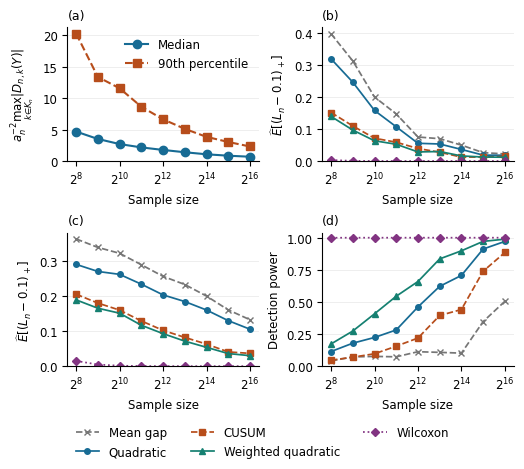

,Mean gap,Quadratic,CUSUM,Weighted quadratic,Wilcoxon
rho,,,,,
0.0,18.99,16.34,9.25,8.32,0.48
0.5,13.21,11.04,5.47,4.97,0.24
0.9,5.41,4.51,2.87,2.80,0.06


,Mean gap,Quadratic,CUSUM,Weighted quadratic,Wilcoxon
rho,,,,,
0.0,11.5,31.2,22.6,63.5,100.0
0.5,10.2,70.7,44.1,89.8,100.0
0.9,51.8,99.2,97.0,99.2,100.0


In [6]:
from IPython.display import HTML, display

results = simulate()
figure = save_results(results, Path.cwd())
display(figure)
plt.close(figure)

sample_size = 2**14
local_location = results["localization_summary"].query("n == @sample_size and signal == 'local'")
local_detection = results["detection_summary"].query("n == @sample_size")
labels = [METHOD_NAMES[method] for method in METHODS]

for data, value, title, decimals in (
    (local_location, "mean_fraction_error", "Mean absolute location error (% of sample size)", 2),
    (local_detection, "power_local", "Detection power (%), nominal level 5%", 1),
):
    table = 100 * data.pivot(index="rho", columns="method", values=value).loc[:, list(METHODS)]
    table.columns = labels
    table.columns.name = None
    table.index.name = "rho"
    html = table.to_html(float_format=lambda value: f"{value:.{decimals}f}")
    display(HTML(html.replace("<thead>", f"<caption>{title}</caption><thead>", 1)))

## Mean change that preserves the ranks

This second experiment corresponds to Section 5.2 of the manuscript. The observations are independent. Under the equal-mean null, observations after the split are uniform on $(-1,1)$. Each observation before the split has the same uniform distribution with probability $1-\theta$ and takes the values $1+R$ and $-1-R$, each with probability $\theta/2$, where $\theta=0.2$ and $R$ is defined above.

The alternative applies $y\mapsto y+(2\Delta_n/\theta)I(y>1)$ to every observation, where $\Delta_n=a_n/2$. This increases the mean before the split without changing either median. The map is strictly increasing, so it preserves the pooled ranks in each paired null and alternative run.

At each sample size, calibrate using 1,000 independent equal-mean samples and evaluate using 2,000 paired samples. The output matches Table 2 of the manuscript. The block distributions differ under the equal-mean null, so this experiment illustrates sensitivity to a change in tail magnitude.

In [7]:
RANK_CHANGE_SAMPLE_SIZES = (2**10, 2**12, 2**14)
RANK_CHANGE_TAIL_PROBABILITY = 0.20
RANK_CHANGE_SHIFT_RATIO = 0.50
RANK_CHANGE_CALIBRATION_SEED = 20261125
RANK_CHANGE_EVALUATION_SEED = 20261126


def rank_change_draw_null(rng, repetitions, n, k0):
    sample = rng.uniform(-1.0, 1.0, size=(repetitions, n))
    left = sample[:, :k0]
    tails = rng.random(left.shape) < RANK_CHANGE_TAIL_PROBABILITY
    radii = radius_from_exponential(rng.exponential(size=int(tails.sum())))
    signs = rng.choice((-1.0, 1.0), size=len(radii))
    left[tails] = signs * (1.0 + radii)
    return sample


def rank_change_calibrate(n, k0, rng):
    maxima = np.empty((CALIBRATION_REPETITIONS, len(METHODS)))
    for start in range(0, CALIBRATION_REPETITIONS, BATCH_SIZE):
        stop = min(start + BATCH_SIZE, CALIBRATION_REPETITIONS)
        _, scores = split_scores(rank_change_draw_null(rng, stop - start, n, k0))
        maxima[start:stop] = np.column_stack([score.max(axis=1) for score in scores])
    order = int(np.ceil((CALIBRATION_REPETITIONS + 1) * (1 - TEST_LEVEL))) - 1
    return np.partition(maxima, order, axis=0)[order, :]


def rank_change_evaluate(n, k0, delta, critical_values, rng):
    false_alarms = np.empty((REPETITIONS, len(METHODS)), dtype=bool)
    detections = np.empty_like(false_alarms)
    location_error = np.empty(false_alarms.shape)
    for start in range(0, REPETITIONS, BATCH_SIZE):
        stop = min(start + BATCH_SIZE, REPETITIONS)
        null = rank_change_draw_null(rng, stop - start, n, k0)
        alternative = null + (2 * delta / RANK_CHANGE_TAIL_PROBABILITY) * (null > 1.0)
        k, null_scores = split_scores(null)
        _, alternative_scores = split_scores(alternative)
        if not np.array_equal(null_scores[-1], alternative_scores[-1]):
            raise AssertionError("The rank contrast changed under the increasing map.")
        false_alarms[start:stop] = np.column_stack(
            [score.max(axis=1) for score in null_scores]
        ) > critical_values
        detections[start:stop] = np.column_stack(
            [score.max(axis=1) for score in alternative_scores]
        ) > critical_values
        location_error[start:stop] = np.column_stack([
            np.abs(k[np.argmax(score, axis=1)] - k0) / n
            for score in alternative_scores
        ])
    return false_alarms, detections, location_error


def rank_change_run_experiment():
    calibration_rng = np.random.default_rng(RANK_CHANGE_CALIBRATION_SEED)
    evaluation_rng = np.random.default_rng(RANK_CHANGE_EVALUATION_SEED)
    results = []
    for n in RANK_CHANGE_SAMPLE_SIZES:
        k0 = 2 * n // 5
        delta = RANK_CHANGE_SHIFT_RATIO * (n * np.log(np.e + n)) ** (1 / P) / n
        critical = rank_change_calibrate(n, k0, calibration_rng)
        false, positive, error = rank_change_evaluate(n, k0, delta, critical, evaluation_rng)
        for j, method in enumerate(METHODS):
            difference = positive[:, j].astype(float) - false[:, j]
            results.append({
                "n": n,
                "k0": k0,
                "delta": delta,
                "method": method,
                "critical_value": critical[j],
                "false_alarm_rate": false[:, j].mean(),
                "se_false_alarm": monte_carlo_se(false[:, j]),
                "power": positive[:, j].mean(),
                "se_power": monte_carlo_se(positive[:, j]),
                "power_minus_size": difference.mean(),
                "se_paired_difference": monte_carlo_se(difference),
                "mean_fraction_error": error[:, j].mean(),
                "se_fraction_error": monte_carlo_se(error[:, j]),
            })
    return pd.DataFrame(results)

In [8]:
mean_change_results = rank_change_run_experiment()
mean_change_results.to_csv(Path.cwd() / "mean_change_summary.csv", index=False)

summary = mean_change_results.assign(
    power_and_size=lambda table: [
        f"{power:.2%} ({size:.2%})".replace("%", "")
        for power, size in zip(table.power, table.false_alarm_rate)
    ],
)
table_2 = summary.pivot(index="n", columns="method", values="power_and_size").loc[:, list(METHODS)]
table_2.columns = [METHOD_NAMES[method] for method in METHODS]
table_2.columns.name = None

from IPython.display import display
display(table_2)

,Mean gap,Quadratic,CUSUM,Weighted quadratic,Wilcoxon
n,,,,,
1024,51.80 (4.55),57.05 (3.85),74.05 (5.05),75.30 (4.45),5.85 (5.85)
4096,78.30 (5.05),85.85 (5.20),94.80 (4.75),95.05 (4.20),4.65 (4.65)
16384,96.75 (4.40),98.40 (4.20),99.70 (4.20),99.50 (4.10),4.50 (4.50)
